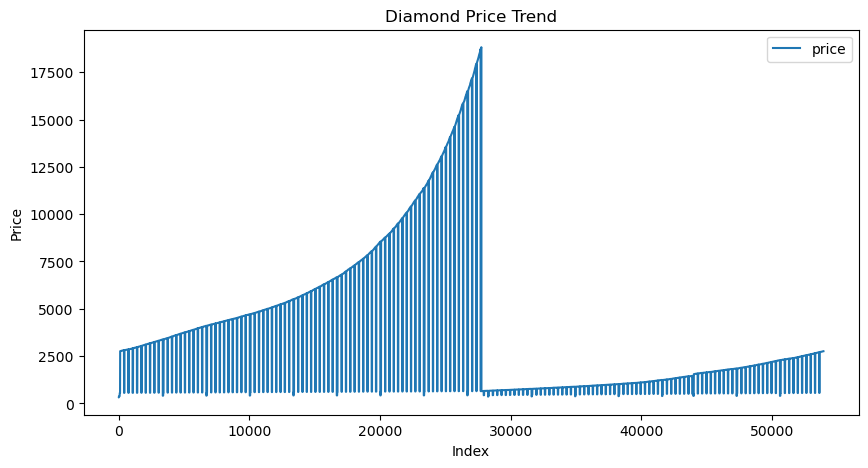

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Load the dataset
file_path = "D:/MCA/Mini Project/Miniproject Datasets for Diamond Valuations/diamonds.csv"  # Update path if needed
df = pd.read_csv(file_path)

# Sorting by index (assuming time sequence is based on index)
df = df.sort_index()

# Visualizing price trend
plt.figure(figsize=(10,5))
plt.plot(df['price'], label='price')
plt.title('Diamond Price Trend')
plt.xlabel('Index')
plt.ylabel('Price')
plt.legend()
plt.show()


In [4]:
# Evaluation Metrics
def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    me = np.mean(actual - predicted)
    mpe = np.mean((actual - predicted) / actual) * 100
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    mapa = np.mean(np.abs(actual - predicted) / (0.5 * (actual + predicted))) * 100
    r2 = r2_score(actual, predicted)
    return mae, rmse, me, mpe, mape, mapa, r2


ARIMA - MAE: 671.5333704115684, RMSE: 764.1281436939545, ME: 493.0964034111976, MPE: 9.098293216357584, MAPE: 43.67905491964284, MAPA: 41.55343396522607, R2: -0.713560274758775


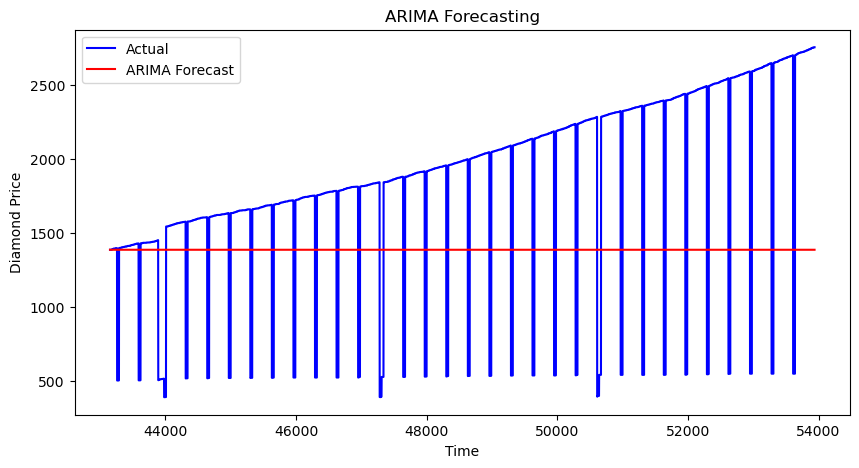

In [9]:
# ARIMA Model
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# Splitting the data into training and testing sets
train_size = int(len(df) * 0.8)
train, test = df['price'][:train_size], df['price'][train_size:]

# Training the ARIMA model
arima_model = ARIMA(train, order=(5,1,0))  # (p,d,q) values
arima_result = arima_model.fit()

# Forecasting
arima_forecast = arima_result.forecast(steps=len(test))

# Evaluating the model
mae, rmse, me, mpe, mape, mapa, r2 = evaluate_forecast(test, arima_forecast)
print(f'ARIMA - MAE: {mae}, RMSE: {rmse}, ME: {me}, MPE: {mpe}, MAPE: {mape}, MAPA: {mapa}, R2: {r2}')

# Plotting results
plt.figure(figsize=(10, 5))
plt.plot(test.index, test, label='Actual', color='blue')
plt.plot(test.index, arima_forecast, label='ARIMA Forecast', color='red')
plt.xlabel('Time')
plt.ylabel('Diamond Price')
plt.title('ARIMA Forecasting')
plt.legend()
plt.show()


SARIMA - MAE: 559.624059721521, RMSE: 644.6281725511519, ME: 354.940188350166, MPE: 0.9404116375800424, MAPE: 40.490846705355615, MAPA: 34.165482396899066, R2: -0.2195105393879615


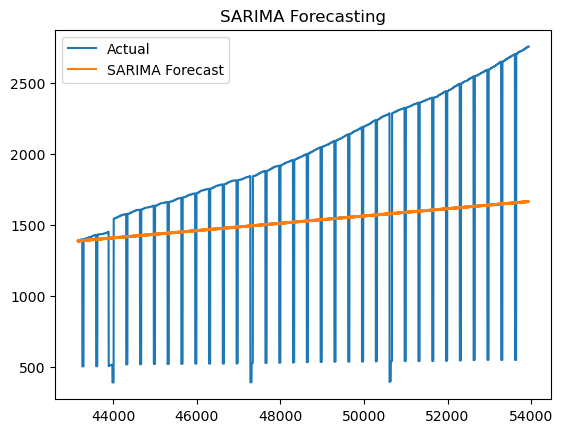

In [22]:
# SARIMA Model
sarima_model = SARIMAX(train, order=(1,1,1), seasonal_order=(1,1,1,12))
sarima_result = sarima_model.fit()

sarima_forecast = sarima_result.forecast(steps=len(test))
mae, rmse, me, mpe, mape, mapa, r2 = evaluate_forecast(test, sarima_forecast)
print(f'SARIMA - MAE: {mae}, RMSE: {rmse}, ME: {me}, MPE: {mpe}, MAPE: {mape}, MAPA: {mapa}, R2: {r2}')

plt.plot(test.index, test, label='Actual')
plt.plot(test.index, sarima_forecast, label='SARIMA Forecast')
plt.legend()
plt.title('SARIMA Forecasting')
plt.show()


Epoch 1/30


C:\Users\vasif\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2697/2697 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 0.0037 - val_loss: 1.6573e-04
Epoch 2/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0013 - val_loss: 5.7198e-05
Epoch 3/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0013 - val_loss: 4.2934e-05
Epoch 4/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0013 - val_loss: 6.9064e-05
Epoch 5/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0012 - val_loss: 4.2376e-05
Epoch 6/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0013 - val_loss: 6.1768e-05
Epoch 7/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0012 - val_loss: 4.1459e-05
Epoch 8/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0012 - val_loss: 1.4461e-04
Epoch 9/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - loss: 0.0010 - val_loss: 7.9065e-05
Epoch 10/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0011 - val_loss: 8.1252e-05
Epoch 11/30
2697/2697 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0011 - val_los

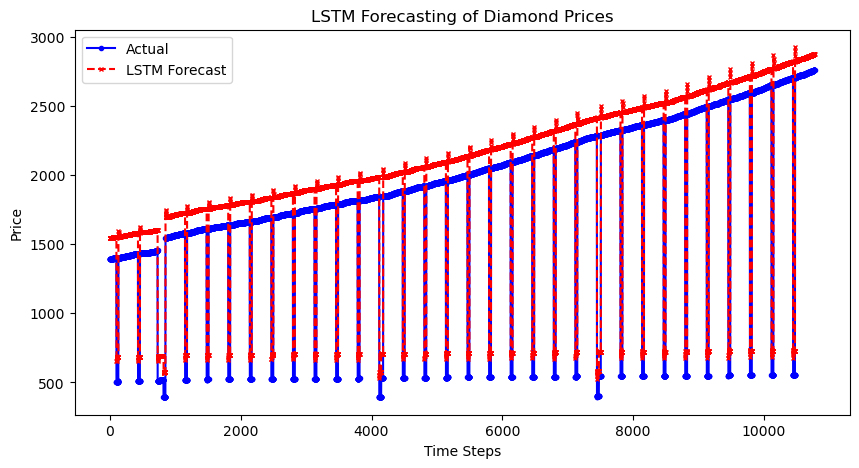

In [35]:
# LSTM Model
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df[['price']])

train_size = int(len(df_scaled) * 0.8)
train, test = df_scaled[:train_size], df_scaled[train_size:]

def create_sequences(data, seq_length=10):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

seq_length = 10
X_train, y_train = create_sequences(train, seq_length)
X_test, y_test = create_sequences(test, seq_length)

model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(seq_length, 1)),
    Dropout(0.2),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model.fit(X_train, y_train, epochs=30, batch_size=16, validation_data=(X_test, y_test))

lstm_pred = model.predict(X_test)
lstm_pred = scaler.inverse_transform(lstm_pred)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1,1))

mae, rmse, me, mpe, mape, mapa, r2 = evaluate_forecast(y_test_actual, lstm_pred)
print(f'LSTM - MAE: {mae}, RMSE: {rmse}, ME: {me}, MPE: {mpe}, MAPE: {mape}, MAPA: {mapa}, R2: {r2}')

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

# Line plot for actual vs forecasted values
plt.plot(y_test_actual, label='Actual', color='blue', linestyle='solid', marker='o', markersize=3)
plt.plot(lstm_pred, label='LSTM Forecast', color='red', linestyle='dashed', marker='x', markersize=3)

# Adding labels and title
plt.xlabel('Time Steps')  # X-axis label
plt.ylabel('Price')  # Y-axis label
plt.title('LSTM Forecasting of Diamond Prices')

# Adding legend
plt.legend()

# Show the plot
plt.show()


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

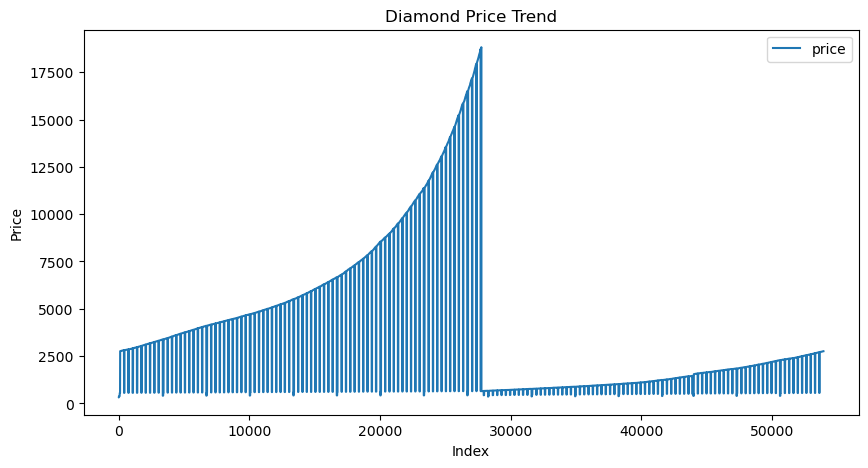

In [38]:
# Load the dataset
file_path = "D:/MCA/Mini Project/Miniproject Datasets for Diamond Valuations/diamonds.csv"  # Update path if needed
df = pd.read_csv(file_path)

# Sorting by index (assuming time sequence is based on index)
df = df.sort_index()

# Visualizing price trend
plt.figure(figsize=(10,5))
plt.plot(df['price'], label='price')
plt.title('Diamond Price Trend')
plt.xlabel('Index')
plt.ylabel('Price')
plt.legend()
plt.show()

In [40]:
# Evaluation Metrics
def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    me = np.mean(actual - predicted)
    mpe = np.mean((actual - predicted) / actual) * 100
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    mapa = np.mean(np.abs(actual - predicted) / (0.5 * (actual + predicted))) * 100
    r2 = r2_score(actual, predicted)
    return mae, rmse, me, mpe, mape, mapa, r2


In [44]:
# ARIMA Model
train_size = int(len(df) * 0.8)
train, test = df['price'][:train_size], df['price'][train_size:]

arima_model = ARIMA(train, order=(5,1,0))  # (p,d,q) values
arima_result = arima_model.fit()

arima_forecast = arima_result.forecast(steps=len(test))
mae, rmse, me, mpe, mape, mapa, r2 = evaluate_forecast(test, arima_forecast)
print(f'ARIMA - MAE: {mae}, RMSE: {rmse}, ME: {me}, MPE: {mpe}, MAPE: {mape}, MAPA: {mapa}, R2: {r2}')

ARIMA - MAE: 671.5333704115684, RMSE: 764.1281436939545, ME: 493.0964034111976, MPE: 9.098293216357584, MAPE: 43.67905491964284, MAPA: 41.55343396522607, R2: -0.713560274758775


In [54]:
# Hybrid ARIMA-LSTM Model
residuals = test - arima_forecast
scaler = MinMaxScaler()
residuals_scaled = scaler.fit_transform(residuals.values.reshape(-1,1))

train_residuals = residuals_scaled[:int(len(residuals_scaled) * 0.8)]
test_residuals = residuals_scaled[int(len(residuals_scaled) * 0.8):]

seq_length = 10

def create_sequences(data, seq_length=10):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

X_train_res, y_train_res = create_sequences(train_residuals, seq_length)
X_test_res, y_test_res = create_sequences(test_residuals, seq_length)

hybrid_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(seq_length, 1)),
    Dropout(0.2),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

hybrid_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
hybrid_model.fit(X_train_res, y_train_res, epochs=50, batch_size=16, validation_data=(X_test_res, y_test_res))

hybrid_res_pred = hybrid_model.predict(X_test_res)
hybrid_res_pred = scaler.inverse_transform(hybrid_res_pred)

hybrid_forecast = arima_forecast[-len(hybrid_res_pred):] + hybrid_res_pred.flatten()
mae, rmse, me, mpe, mape, mapa, r2 = evaluate_forecast(test[-len(hybrid_forecast):], hybrid_forecast)
print(f'Hybrid ARIMA-LSTM - MAE: {mae}, RMSE: {rmse}, ME: {me}, MPE: {mpe}, MAPE: {mape}, MAPA: {mapa}, R2: {r2}')


Epoch 1/50


C:\Users\vasif\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


539/539 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0401 - val_loss: 0.0122
Epoch 2/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0083 - val_loss: 0.0095
Epoch 3/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0075 - val_loss: 0.0059
Epoch 4/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0045 - val_loss: 0.0058
Epoch 5/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0046 - val_loss: 0.0046
Epoch 6/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0032 - val_loss: 0.0043
Epoch 7/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0038 - val_loss: 0.0042
Epoch 8/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0033 - val_loss: 0.0042
Epoch 9/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0040 - val_loss: 0.0041
Epoch 10/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0026 - val_loss: 0.0040
Epoch 11/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0029 - val_loss: 0.0053
Epoch 12/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.

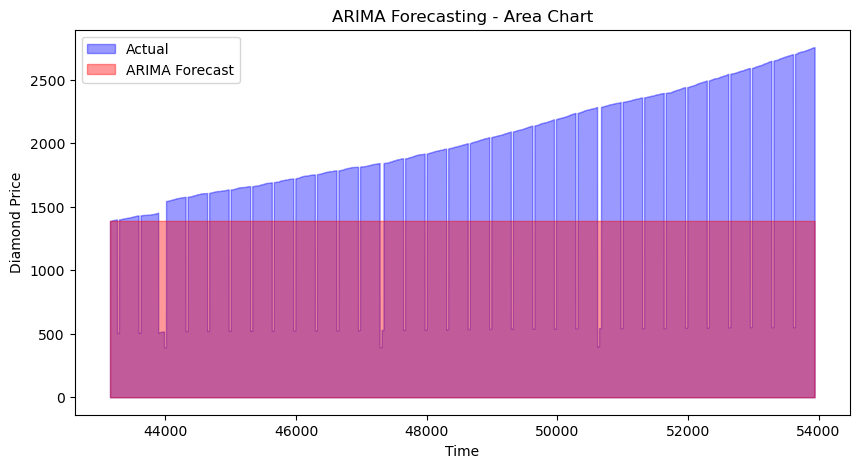

In [19]:
plt.figure(figsize=(10, 5))
plt.fill_between(test.index, test, color='blue', alpha=0.4, label='Actual')
plt.fill_between(test.index, arima_forecast, color='red', alpha=0.4, label='ARIMA Forecast')
plt.xlabel('Time')
plt.ylabel('Diamond Price')
plt.title('ARIMA Forecasting - Area Chart')
plt.legend()
plt.show()


C:\Users\vasif\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.0317 - val_loss: 0.0100
Epoch 2/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0076 - val_loss: 0.0072
Epoch 3/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0060 - val_loss: 0.0070
Epoch 4/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0057 - val_loss: 0.0056
Epoch 5/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0043 - val_loss: 0.0049
Epoch 6/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0040 - val_loss: 0.0049
Epoch 7/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0037 - val_loss: 0.0041
Epoch 8/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0035 - val_loss: 0.0041
Epoch 9/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0029 - val_loss: 0.0064
Epoch 10/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0027 - val_loss: 0.0051
Epoch 11/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0034 - val_loss: 0.0041
Epoch 12/50
539/539 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

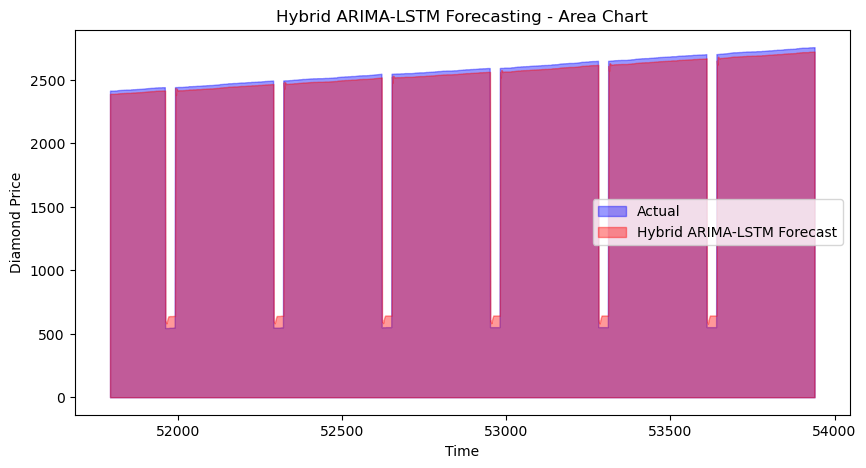

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Calculate residuals
residuals = test - arima_forecast

# Normalize residuals
scaler = MinMaxScaler()
residuals_scaled = scaler.fit_transform(residuals.values.reshape(-1, 1))

# Splitting into train and test sets
train_residuals = residuals_scaled[:int(len(residuals_scaled) * 0.8)]
test_residuals = residuals_scaled[int(len(residuals_scaled) * 0.8):]

# Creating sequences
seq_length = 10
def create_sequences(data, seq_length=10):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

X_train_res, y_train_res = create_sequences(train_residuals, seq_length)
X_test_res, y_test_res = create_sequences(test_residuals, seq_length)

# Define LSTM model
hybrid_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(seq_length, 1)),
    Dropout(0.2),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

hybrid_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
hybrid_model.fit(X_train_res, y_train_res, epochs=50, batch_size=16, validation_data=(X_test_res, y_test_res))

# Predict residuals
hybrid_res_pred = hybrid_model.predict(X_test_res)
hybrid_res_pred = scaler.inverse_transform(hybrid_res_pred)

# Compute final hybrid forecast
hybrid_forecast = arima_forecast[-len(hybrid_res_pred):] + hybrid_res_pred.flatten()

# Evaluate model
mae, rmse, me, mpe, mape, mapa, r2 = evaluate_forecast(test[-len(hybrid_forecast):], hybrid_forecast)
print(f'Hybrid ARIMA-LSTM - MAE: {mae}, RMSE: {rmse}, ME: {me}, MPE: {mpe}, MAPE: {mape}, MAPA: {mapa}, R2: {r2}')

# Plot area chart
plt.figure(figsize=(10, 5))
plt.fill_between(test.index[-len(hybrid_forecast):], test[-len(hybrid_forecast):], color='blue', alpha=0.4, label='Actual')
plt.fill_between(test.index[-len(hybrid_forecast):], hybrid_forecast, color='red', alpha=0.4, label='Hybrid ARIMA-LSTM Forecast')
plt.xlabel('Time')
plt.ylabel('Diamond Price')
plt.title('Hybrid ARIMA-LSTM Forecasting - Area Chart')
plt.legend()
plt.show()

In [25]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

# Line plot for actual vs forecasted values
plt.plot(y_test_actual, label='Actual', color='blue', linestyle='solid', marker='o', markersize=3)
plt.plot(lstm_pred, label='LSTM Forecast', color='red', linestyle='dashed', marker='x', markersize=3)

# Adding labels and title
plt.xlabel('Time Steps')  # X-axis label
plt.ylabel('Price')  # Y-axis label
plt.title('LSTM Forecasting of Diamond Prices')

# Adding legend
plt.legend()

# Show the plot
plt.show()


NameError: name 'y_test_actual' is not defined

<Figure size 1000x500 with 0 Axes>

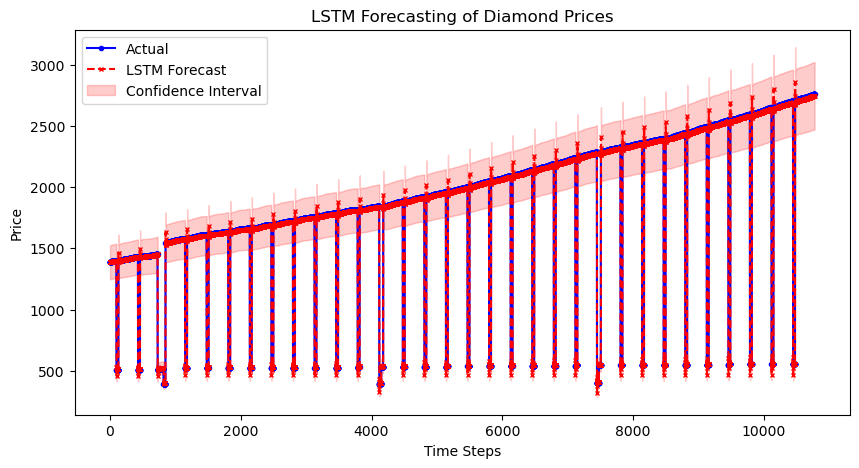

In [29]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

# Line plot for actual vs forecasted values
plt.plot(y_test_actual, label='Actual', color='blue', linestyle='solid', marker='o', markersize=3)
plt.plot(lstm_pred, label='LSTM Forecast', color='red', linestyle='dashed', marker='x', markersize=3)

# Adding an area chart (shaded region) for confidence bounds
confidence_interval = 0.1 * np.abs(lstm_pred)  # Adjust the multiplier as needed
plt.fill_between(range(len(lstm_pred)), lstm_pred.flatten() - confidence_interval.flatten(), 
                 lstm_pred.flatten() + confidence_interval.flatten(), color='red', alpha=0.2, label='Confidence Interval')

# Adding labels and title
plt.xlabel('Time Steps')  # X-axis label
plt.ylabel('Price')  # Y-axis label
plt.title('LSTM Forecasting of Diamond Prices')

# Adding legend
plt.legend()

# Show the plot
plt.show()


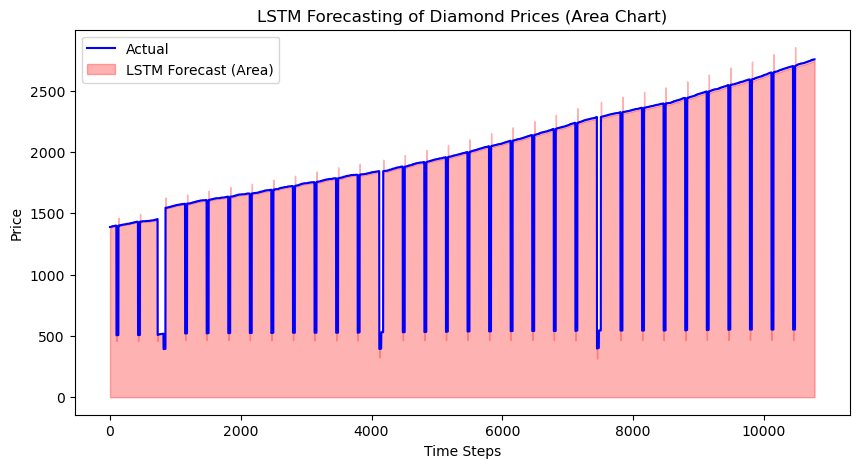

In [33]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

# Plot actual values as a line plot
plt.plot(y_test_actual, label='Actual', color='blue')

# Area plot for LSTM forecast
plt.fill_between(range(len(lstm_pred)), lstm_pred.flatten(), color='red', alpha=0.3, label='LSTM Forecast (Area)')

# Adding labels and title
plt.xlabel('Time Steps')  # X-axis label
plt.ylabel('Price')  # Y-axis label
plt.title('LSTM Forecasting of Diamond Prices (Area Chart)')

# Adding legend
plt.legend()

# Show the plot
plt.show()
